# Previsão intenção de compra

# Introdução

## Sobre o projeto

Problema: lojas virtuais recebem muitos visitantes, mas nem todos realizam compras. O objetivo é identificar padrões de comportamento que ajudem a prever quais visitantes têm maior probabilidade de concluir uma compra.

Objetivo do modelo: classificar cada sessão de
navegação em uma das duas categorias:


*   True: O visitante realizou uma compra.
*   False: O visitante não realizou uma compra.


Tipo de aprendizado: aprendizado supervisionado.

Tipo de problema: classificação binária.

## Sobre o Dataset - Online Shoppers Purchasing Intention Dataset

https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention

### Significado das variáveis

Administrative - Páginas administrativas visitadas

Administrative_Duration	- Tempo nessas páginas

Informational	- Páginas informativas visitadas

Informational_Duration	- Tempo nessas páginas

ProductRelated -	Páginas relacionadas a produtos visitadas

ProductRelated_Duration	- Tempo nessas páginas

BounceRates -	Taxa de rejeição da sessão

ExitRates	- Taxa de saída das páginas

PageValues	- Valor médio atribuído às páginas

SpecialDay -	Proximidade de datas especiais
Month	Mês da sessão

OperatingSystems	- Sistema operacional

Browser - 	Navegador

Region	- Região geográfica

TrafficType -	Origem ou tipo de tráfego

VisitorType -	Tipo de visitante

Weekend -	Se a sessão ocorreu no fim de semana

Revenue -	Se houve compra

# Importação das bibliotecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Carregamento dos dados

In [ ]:
# carregar o dataset
dataset = fetch_ucirepo(id=468)

# separar as variáveis preditoras e a target
X = dataset.data.features
y= dataset.data.targets

# Juntar tudo em um único DataFrame
df = pd.concat([X, y], axis=1)

# Conhecendo Dados

In [ ]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
df.shape

(12330, 18)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [ ]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [ ]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


# Análise exploratória dos dados (EDA)

In [ ]:
df['Revenue'].value_counts(normalize=True) * 100

,proportion
Revenue,
False,84.525547
True,15.474453


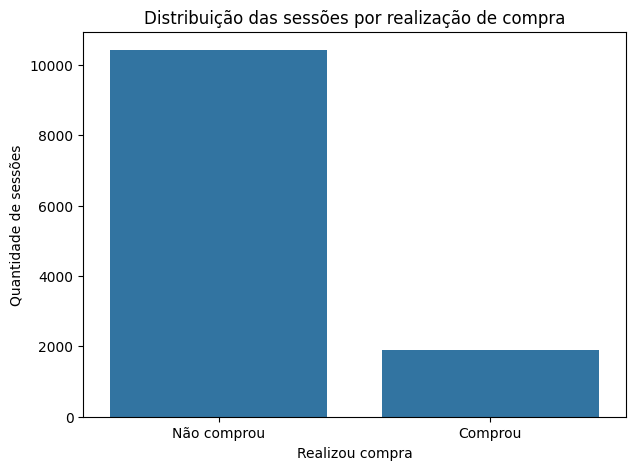

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Revenue')

plt.title('Distribuição das sessões por realização de compra')
plt.xlabel('Realizou compra')
plt.ylabel('Quantidade de sessões')
plt.xticks([0, 1], ['Não comprou', 'Comprou'])

plt.show()

In [ ]:
df.duplicated().sum()

np.int64(125)

In [ ]:
print("Meses:")
print(df['Month'].value_counts())

print("\n tipos de visitantes:")
print(df['VisitorType'].value_counts())

Meses:
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

 tipos de visitantes:
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64


# Pré-processamento dos dados

In [ ]:
# transformação na linha
df = df.drop_duplicates().copy()

In [ ]:
df.describe(include='all')

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205,12205.000000,12205.000000,12205.000000,12205.000000,12205,12205,12205
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3329,NaN,NaN,NaN,NaN,10431,9346,10297
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,NaN,2.124211,2.357804,3.153298,4.073904,NaN,NaN,NaN
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,NaN,0.906823,1.710114,2.402340,4.016654,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


# Preparação dos dados

Separação do Target das variáveis preditoras

In [ ]:
# Separar as variáveis preditoras
X = df.drop(columns=['Revenue'])

# Separar o target
y = df['Revenue'].astype(int)

print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

Dimensões de X: (12205, 17)
Dimensões de y: (12205,)


70% treinamento, 15% validação, 15% teste - hold out

In [ ]:
from sklearn.model_selection import train_test_split

# Primeiro separar 70% para treinamento e 30% para validação
X_train, X_temp, y_train, y_temp = train_test_split(
    X,y,
    test_size=0.30,
    random_state=42,
    stratify=y # ajuda a manter a proporção
)

# Segundo dividir os 30% restantes igualmente
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Conferir os tamanhos
print("Treinamento:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treinamento: (8543, 17)
Validação: (1831, 17)
Teste: (1831, 17)


Transformação nas colunas

In [ ]:
# Colunas cetegóricas
colunas_categoricas = ['Month', 'VisitorType']

# Colunas numéricas
colunas_numericas = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Colunas booleanas
colunas_booleanas =  ['Weekend']

print("Categóricas:", colunas_categoricas)
print("Numéricas:", colunas_numericas)
print("Booleanas:", colunas_booleanas)

Categóricas: ['Month', 'VisitorType']
Numéricas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Booleanas: ['Weekend']


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
preprocessador = ColumnTransformer(
    transformers=[
        ('numericas', StandardScaler(), colunas_numericas),
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
        ('booleanas', 'passthrough', colunas_booleanas)
    ]
)

transformação de coluna

In [ ]:
# converter a variável booleana para 0 e 1
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

for conjunto in [X_train, X_val, X_test]:
  conjunto['Weekend'] = conjunto['Weekend'].astype(int)

In [ ]:
colunas_numericas.append('Weekend')

preprocessador = ColumnTransformer(
    transformers=[
        ('numericas', StandardScaler(), colunas_numericas),
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), colunas_categoricas)
    ]
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

Criação do Pipeline completo - unindo o pré-processamento com o algoritmo Random Forest

In [ ]:
modelo_rf = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('classificador', RandomForestClassifier(
        n_estimators=200, #quantidade de arvores criadas
        random_state=42,
        class_weight='balanced' #ajusta os pesos das classes pois existem muitas sessões sem compra doq com compra
    ))
])

treinamento do modelo

In [ ]:
modelo_rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessador',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['Administrative',
                                                   'Administrative_Duration',
                                                   'Informational',
                                                   'Informational_Duration',
                                                   'ProductRelated',
                                                   'ProductRelated_Duration',
                                                   'BounceRates', 'ExitRates',
                                                   'PageValues', 'SpecialDay',
                                                   'OperatingSystems',
                                                   'Browser', 'Region',
                                                   'TrafficType', 'Weekend']),
                                                 ('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Month', 'VisitorType'])])),
                ('classificador',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

Aplicando métricas de desempenho ao conjunto de validação

In [ ]:
y_val_pred = modelo_rf.predict(X_val)

Acurácia

In [ ]:
acuracia = accuracy_score(y_val, y_val_pred)

print(f'Acurácia: {acuracia:.2%}')

Acurácia: 90.17%


Precision, Recall, F1-score

In [ ]:
print(classification_report(
    y_val,
    y_val_pred,
    target_names=['Não comprou', 'Comprou']
))

              precision    recall  f1-score   support

 Não comprou       0.92      0.97      0.94      1545
     Comprou       0.76      0.54      0.63       286

    accuracy                           0.90      1831
   macro avg       0.84      0.75      0.79      1831
weighted avg       0.89      0.90      0.89      1831



Matriz de confusão

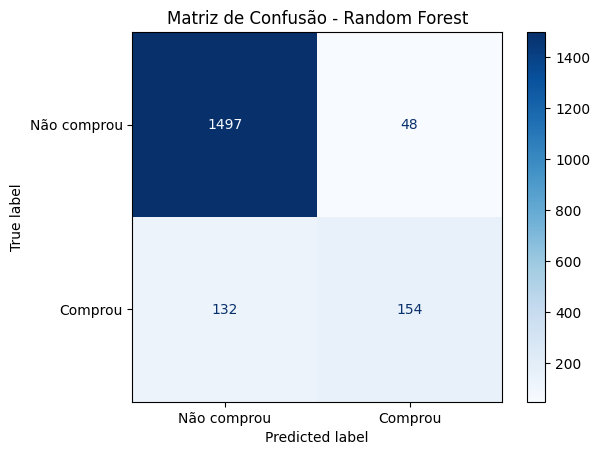

In [ ]:
matriz = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Não comprou', 'Comprou']
)

disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - Random Forest')
plt.show()

Ajustando o modelo

              precision    recall  f1-score   support

 Não comprou       0.93      0.94      0.94      1545
     Comprou       0.68      0.64      0.66       286

    accuracy                           0.90      1831
   macro avg       0.81      0.79      0.80      1831
weighted avg       0.89      0.90      0.90      1831



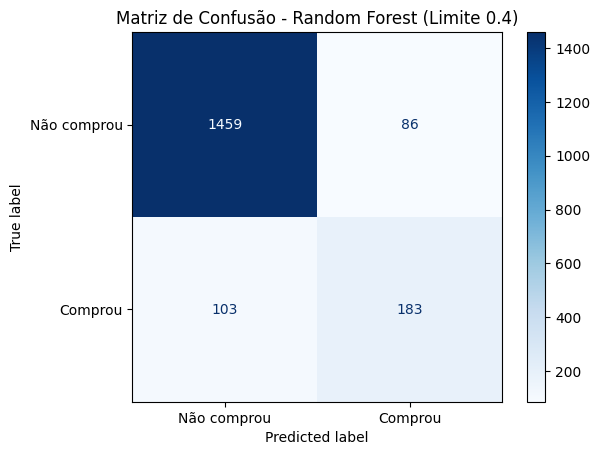

In [ ]:
# ajustar o limite de decisão (threshold)

# Obter as probabilidades de cada classe
probabilidades = modelo_rf.predict_proba(X_val)

# Selecionar as probabilidades da classe Comprou (1)
prob_compra = probabilidades[:, 1]

# Definir um novo limite de decisão

limite = 0.40

# Gerar novas previsões
y_val_pred_ajustado = (prob_compra >= limite).astype(int)

# Avaliar os resultados
print(classification_report(
    y_val,
    y_val_pred_ajustado,
    target_names=['Não comprou', 'Comprou']
))

# Exibir a nova matriz de confusão
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_ajustado,
    cmap='Blues',
    display_labels=['Não comprou', 'Comprou']
)

plt.title('Matriz de Confusão - Random Forest (Limite 0.4)')
plt.show()


testando outros limites

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

limites = [0.30, 0.35, 0.40, 0.45, 0.50]

for limite in limites:
  previsoes = (prob_compra >= limite).astype(int)

  precisao = precision_score(y_val, previsoes)
  recall = recall_score(y_val, previsoes)
  f1 = f1_score(y_val, previsoes)

  print(f'\nLimite: {limite}')
  print(f'Precisão: {precisao:.2%}')
  print(f'Recall: {recall:.2%}')
  print(f'F1-score: {f1:.2%}')


Limite: 0.3
Precisão: 62.57%
Recall: 73.08%
F1-score: 67.42%

Limite: 0.35
Precisão: 66.23%
Recall: 69.93%
F1-score: 68.03%

Limite: 0.4
Precisão: 68.03%
Recall: 63.99%
F1-score: 65.95%

Limite: 0.45
Precisão: 69.92%
Recall: 57.69%
F1-score: 63.22%

Limite: 0.5
Precisão: 75.61%
Recall: 54.20%
F1-score: 63.14%


Para esse projeto, utilizarei o limite 0,35 por apresentar o maior F1-score de  68,03%

O F1-score metrifica o equilíbrio entre Precisão e Recall

# Avaliação final com o conjunto de teste

In [ ]:
# Obter as probabilidades de compra no conjunto de teste
probabilidades_teste = modelo_rf.predict_proba(X_test)

# Selecionar as probabilidades da classe Comprou (1)
prob_compra_teste = probabilidades_teste[:, 1]

# Aplicar o limite escolhido na validação
limite_final = 0.35

# Gerar as previsões finais
y_test_pred =  (prob_compra_teste >= limite_final).astype(int)

In [ ]:
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['Não comprou', 'Comprou']
))

# Acurácia
acuracia_teste = accuracy_score(y_test, y_test_pred)

print(f'Acurácia final: {acuracia_teste:.2%}')

              precision    recall  f1-score   support

 Não comprou       0.95      0.93      0.94      1545
     Comprou       0.66      0.73      0.69       286

    accuracy                           0.90      1831
   macro avg       0.81      0.83      0.82      1831
weighted avg       0.90      0.90      0.90      1831

Acurácia final: 89.95%


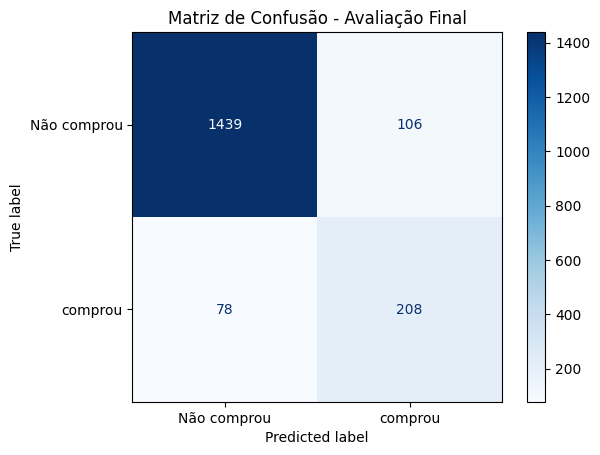

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=['Não comprou', 'comprou'],
    cmap='Blues'
)

plt.title('Matriz de Confusão - Avaliação Final')
plt.show()

previsão individual

In [ ]:
# Selecionar uma sessão do conjunto de teste
amostra = X_test.iloc[[0]]

# Obter a probabilidade de compra
probabilidade = modelo_rf.predict_proba(amostra)[0][1]

# Aplicar o limite escolhido
previsao = int(probabilidade >= 0.35)

# Consultar o resultado real
resultado_real= y_test.iloc[0]

# Exibir os resultados
print(f'Probabilidade de compra: {probabilidade:.2%}')

print('Previsão do modelo:',
      'Comprou' if previsao == 1 else 'Não comprou')

print('Resultado real:',
      'Comrpou' if resultado_real == 1 else 'Não comprou')

Probabilidade de compra: 0.00%
Previsão do modelo: Não comprou
Resultado real: Não comprou
